In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
pd.options.display.float_format = '{:.2f}'.format

In [120]:
data = pd.read_csv('data/creditcard.csv')
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.00,-1.36,-0.07,2.54,1.38,-0.34,0.46,0.24,0.10,0.36,...,-0.02,0.28,-0.11,0.07,0.13,-0.19,0.13,-0.02,149.62,0
1,0.00,1.19,0.27,0.17,0.45,0.06,-0.08,-0.08,0.09,-0.26,...,-0.23,-0.64,0.10,-0.34,0.17,0.13,-0.01,0.01,2.69,0
2,1.00,-1.36,-1.34,1.77,0.38,-0.50,1.80,0.79,0.25,-1.51,...,0.25,0.77,0.91,-0.69,-0.33,-0.14,-0.06,-0.06,378.66,0
3,1.00,-0.97,-0.19,1.79,-0.86,-0.01,1.25,0.24,0.38,-1.39,...,-0.11,0.01,-0.19,-1.18,0.65,-0.22,0.06,0.06,123.50,0
4,2.00,-1.16,0.88,1.55,0.40,-0.41,0.10,0.59,-0.27,0.82,...,-0.01,0.80,-0.14,0.14,-0.21,0.50,0.22,0.22,69.99,0


In [121]:
data.shape

(284807, 31)

In [122]:
data.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [123]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [124]:
data.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,...,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00
mean,94813.86,0.00,0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,...,0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,88.35,0.00
std,47488.15,1.96,1.65,1.52,1.42,1.38,1.33,1.24,1.19,1.10,...,0.73,0.73,0.62,0.61,0.52,0.48,0.40,0.33,250.12,0.04
min,0.00,-56.41,-72.72,-48.33,-5.68,-113.74,-26.16,-43.56,-73.22,-13.43,...,-34.83,-10.93,-44.81,-2.84,-10.30,-2.60,-22.57,-15.43,0.00,0.00
25%,54201.50,-0.92,-0.60,-0.89,-0.85,-0.69,-0.77,-0.55,-0.21,-0.64,...,-0.23,-0.54,-0.16,-0.35,-0.32,-0.33,-0.07,-0.05,5.60,0.00
50%,84692.00,0.02,0.07,0.18,-0.02,-0.05,-0.27,0.04,0.02,-0.05,...,-0.03,0.01,-0.01,0.04,0.02,-0.05,0.00,0.01,22.00,0.00
75%,139320.50,1.32,0.80,1.03,0.74,0.61,0.40,0.57,0.33,0.60,...,0.19,0.53,0.15,0.44,0.35,0.24,0.09,0.08,77.16,0.00
max,172792.00,2.45,22.06,9.38,16.88,34.80,73.30,120.59,20.01,15.59,...,27.20,10.50,22.53,4.58,7.52,3.52,31.61,33.85,25691.16,1.00


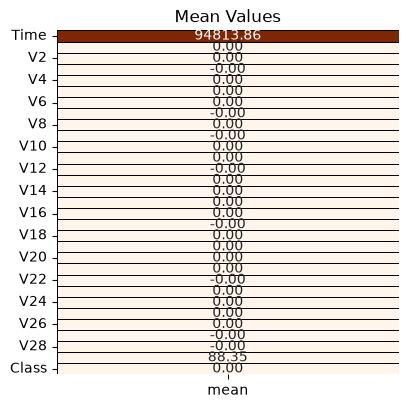

In [125]:
#create a subplot with 1 row, 1 col and figure size (5,5)
fig,ax = plt.subplots(nrows = 1,ncols = 1,figsize = (5,5))

colors = ['#FF781F','#2D2926']
plt.subplot(1,1,1)
sns.heatmap(data.describe().T[['mean']],cmap = 'Oranges',annot = True,fmt = '.2f',linecolor = 'black',linewidths = 0.4,cbar = False);
plt.title('Mean Values');

fig.tight_layout(pad = 4)

In [126]:
data[['Time', 'Amount', 'Class']].describe()

,Time,Amount,Class
count,284807.00,284807.00,284807.00
mean,94813.86,88.35,0.00
std,47488.15,250.12,0.04
min,0.00,0.00,0.00
25%,54201.50,5.60,0.00
50%,84692.00,22.00,0.00
75%,139320.50,77.16,0.00
max,172792.00,25691.16,1.00


In [127]:

data.isnull().sum()


Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [128]:

data['Class'].value_counts()


Class
0    284315
1       492
Name: count, dtype: int64

C:\Users\engze\AppData\Local\Temp\ipykernel_35068\1363076188.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["Amount"],color = colors[0])
C:\Users\engze\AppData\Local\Temp\ipykernel_35068\1363076188.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data["Time"],color = colors[0])


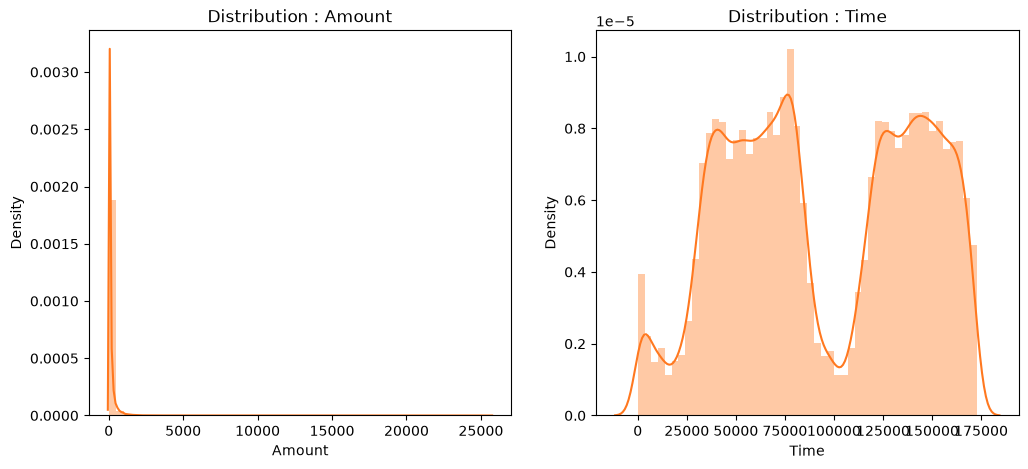

In [129]:

fig, ax = plt.subplots(nrows = 1,ncols = 2,figsize = (12,5))
plt.subplot(1,2,1)
sns.distplot(data["Amount"],color = colors[0])
title = 'Distribution : ' + 'Amount'
plt.title(title)


plt.subplot(1,2,2)
sns.distplot(data["Time"],color = colors[0])
title = 'Distribution : ' + 'Time'
plt.title(title)
plt.show()



C:\Users\engze\AppData\Local\Temp\ipykernel_35068\2595843792.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = 'Class',y = 'Amount', data = data.sort_values(ascending = False,by = 'Amount').iloc[:5],palette = colors,edgecolor = 'black');
C:\Users\engze\AppData\Local\Temp\ipykernel_35068\2595843792.py:3: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  ax = sns.barplot(x = 'Class',y = 'Amount', data = data.sort_values(ascending = False,by = 'Amount').iloc[:5],palette = colors,edgecolor = 'black');
C:\Users\engze\AppData\Local\Temp\ipykernel_35068\2595843792.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = 'Class',y = 'Am

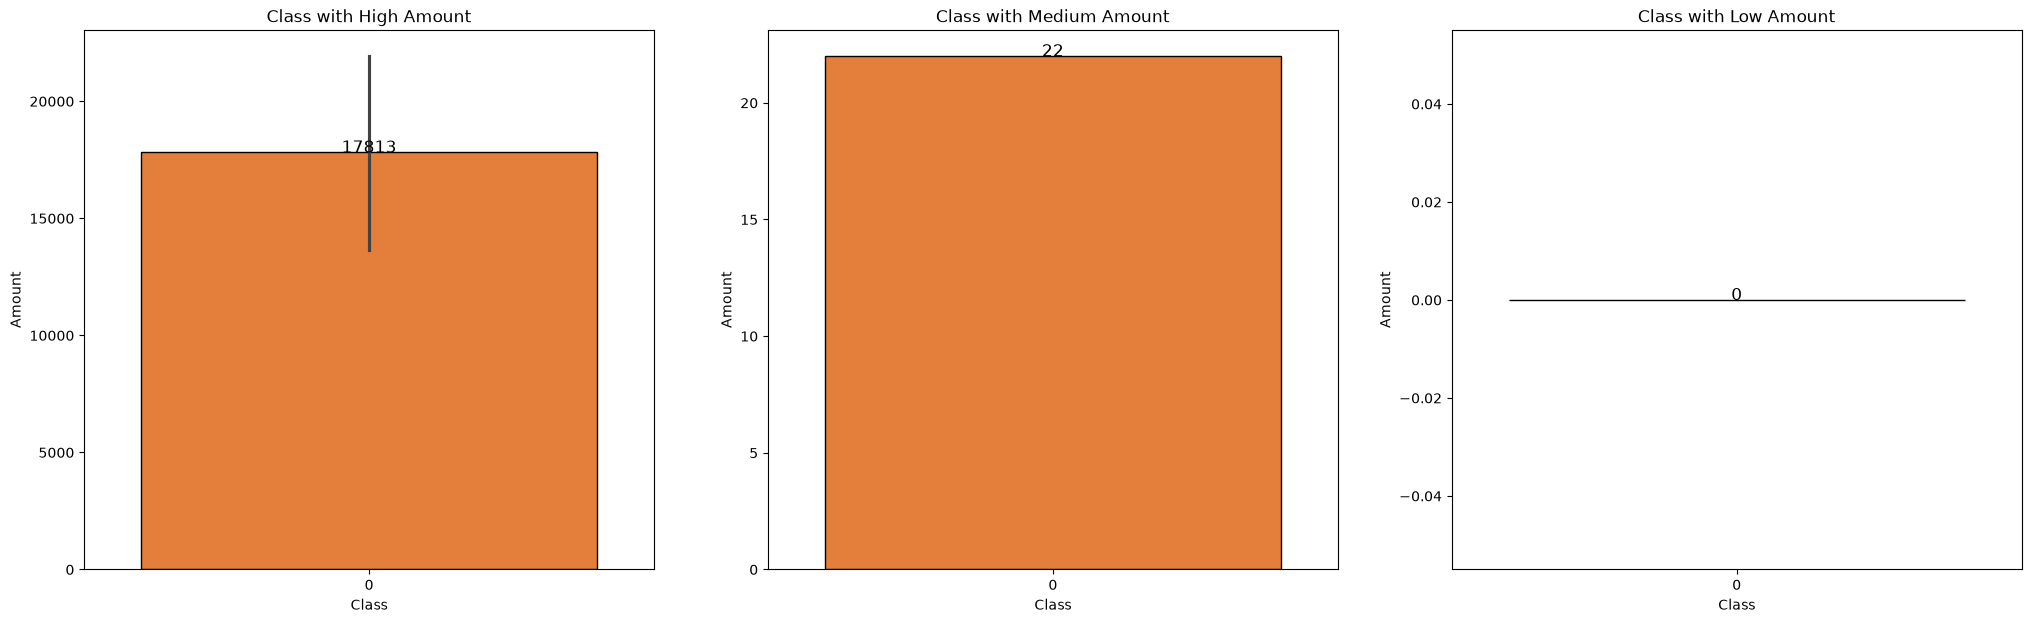

In [130]:
fig = plt.subplots(nrows = 1,ncols = 3,figsize = (25,7))
plt.subplot(1,3,1)
ax = sns.barplot(x = 'Class',y = 'Amount', data = data.sort_values(ascending = False,by = 'Amount').iloc[:5],palette = colors,edgecolor = 'black');
plt.title('Class with High Amount')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)

plt.subplot(1,3,2)
ax = sns.barplot(x = 'Class',y = 'Amount', data = data.sort_values(ascending = False,by = 'Amount').iloc[142403:142408],palette = colors,edgecolor = 'black');
plt.title('Class with Medium Amount')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)

plt.subplot(1,3,3)
ax = sns.barplot(x = 'Class',y = 'Amount', data = data.sort_values(ascending = False,by = 'Amount').iloc[284802:284807],palette = colors,edgecolor = 'black');
plt.title('Class with Low Amount')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)
plt.show()

C:\Users\engze\AppData\Local\Temp\ipykernel_35068\2132530022.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = 'Class',y = 'Time', data = data.sort_values(ascending = False,by = 'Time').iloc[:5],palette = colors,edgecolor = 'black');
C:\Users\engze\AppData\Local\Temp\ipykernel_35068\2132530022.py:3: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  ax = sns.barplot(x = 'Class',y = 'Time', data = data.sort_values(ascending = False,by = 'Time').iloc[:5],palette = colors,edgecolor = 'black');
C:\Users\engze\AppData\Local\Temp\ipykernel_35068\2132530022.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = 'Class',y = 'Time', dat

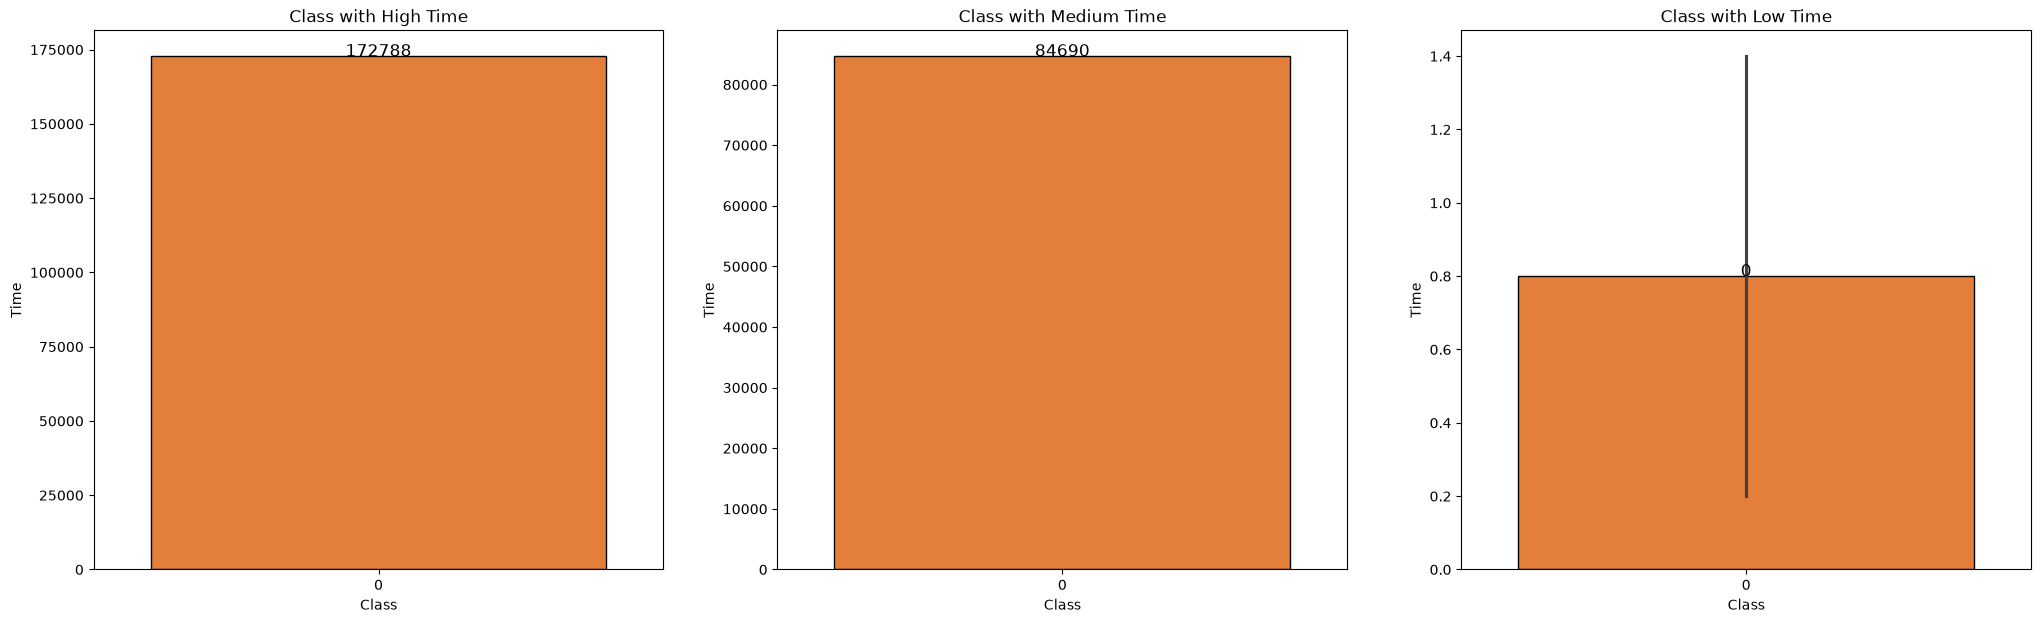

In [131]:
fig = plt.subplots(nrows = 1,ncols = 3,figsize = (25,7))
plt.subplot(1,3,1)
ax = sns.barplot(x = 'Class',y = 'Time', data = data.sort_values(ascending = False,by = 'Time').iloc[:5],palette = colors,edgecolor = 'black');
plt.title('Class with High Time')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)

plt.subplot(1,3,2)
ax = sns.barplot(x = 'Class',y = 'Time', data = data.sort_values(ascending = False,by = 'Time').iloc[142403:142408],palette = colors,edgecolor = 'black');
plt.title('Class with Medium Time')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)

plt.subplot(1,3,3)
ax = sns.barplot(x = 'Class',y = 'Time', data = data.sort_values(ascending = False,by = 'Time').iloc[284802:284807],palette = colors,edgecolor = 'black');
plt.title('Class with Low Time')
for rect in ax.patches:
    ax.text(rect.get_x() + rect.get_width()/2, rect.get_height(), int(rect.get_height()), 
            horizontalalignment='center', fontsize = 12)
plt.show()

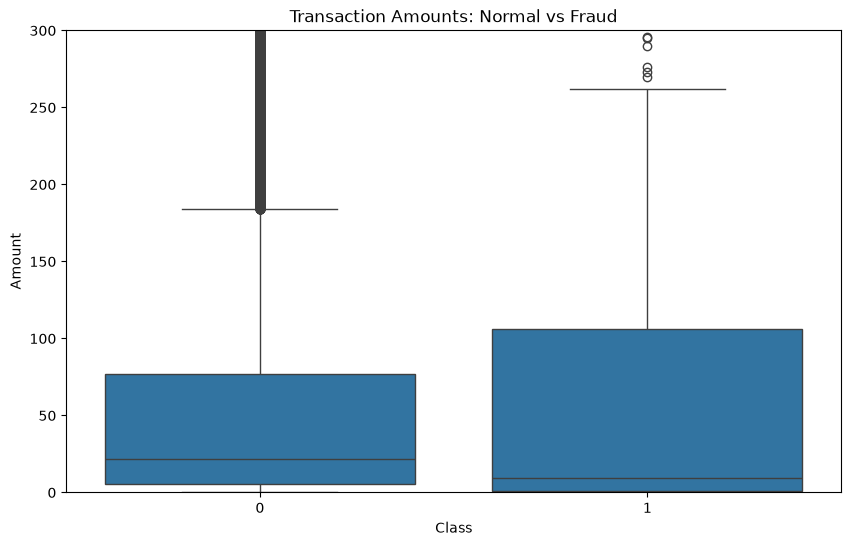

In [132]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=data, x='Class', y='Amount')

plt.ylim(0, 300)

plt.title('Transaction Amounts: Normal vs Fraud')
plt.show()

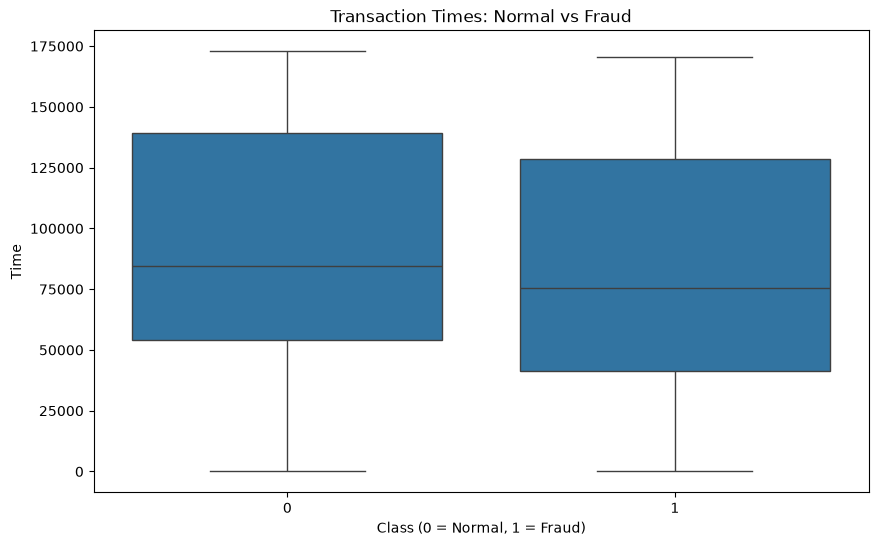

In [133]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=data, x='Class', y='Time')

plt.title('Transaction Times: Normal vs Fraud')
plt.xlabel('Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Time')

plt.show()

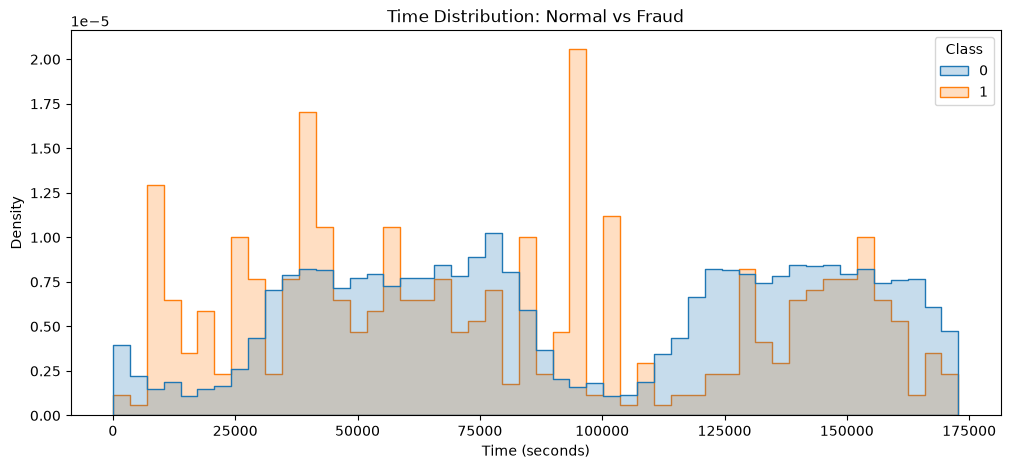

In [134]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=data,
    x='Time',
    hue='Class',
    bins=50,
    stat='density',
    common_norm=False,
    element='step'
)

plt.title('Time Distribution: Normal vs Fraud')
plt.xlabel('Time (seconds)')
plt.ylabel('Density')
plt.show()

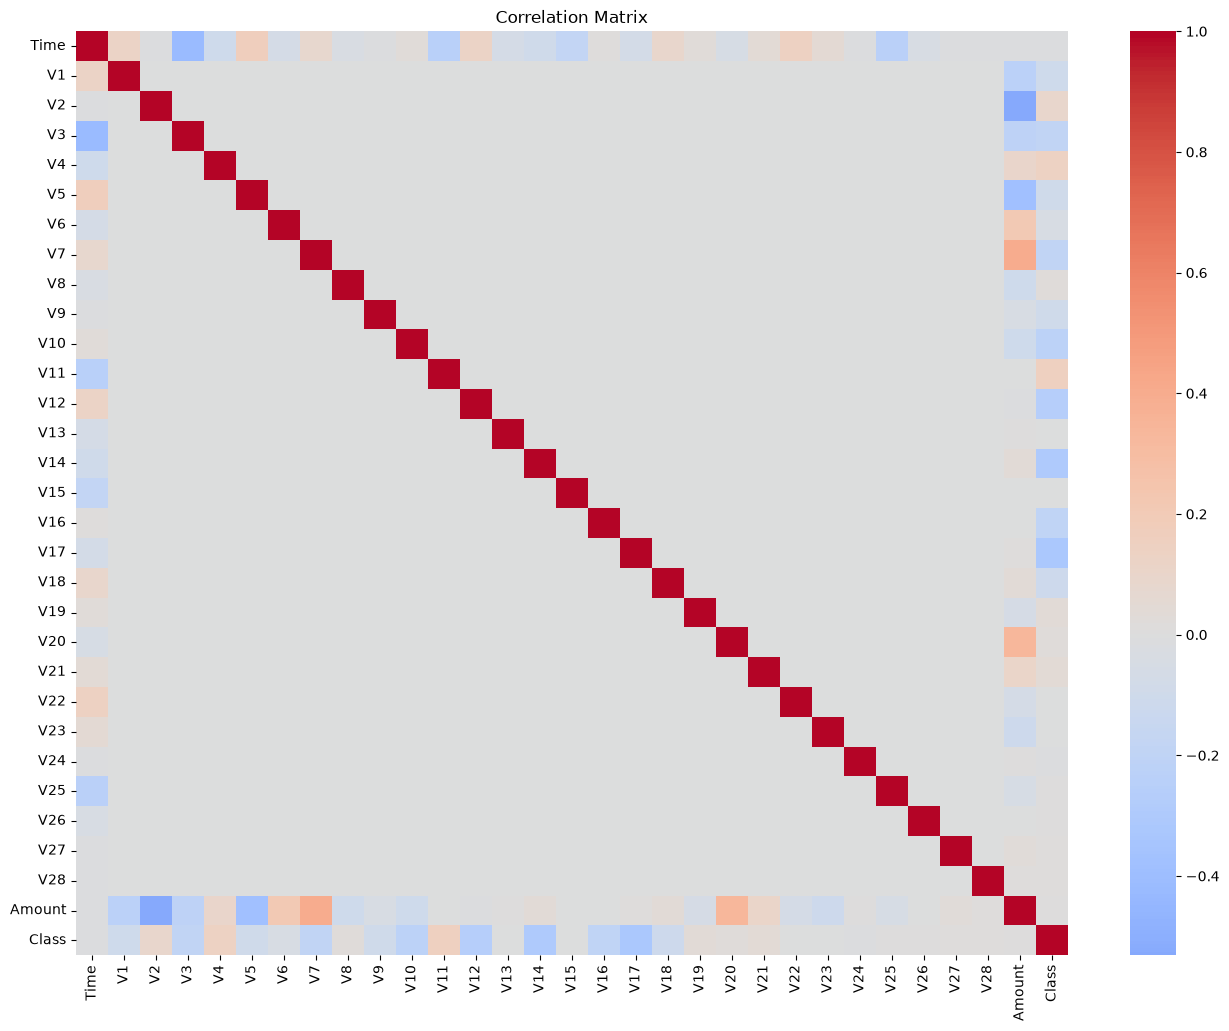

In [135]:
plt.figure(figsize=(16, 12))

corr_matrix = data.corr()

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix')
plt.show()

In [136]:
from sklearn.preprocessing import MinMaxScaler

X =  data.copy(deep = True)


scaler = MinMaxScaler()

In [137]:

col = list(data.columns)
X_scaled = X.copy()

for i in col:
    X_scaled[i] = scaler.fit_transform(X_scaled[[i]]) # Normalization
X_scaled.drop(columns = 'Class',inplace = True) 
X_scaled.head()

X_scaled.head()

C:\Users\engze\AppData\Local\Temp\ipykernel_35068\795653332.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_scaled.drop(columns = 'Class',inplace = True)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.00,0.94,0.77,0.88,0.31,0.76,0.27,0.27,0.79,0.48,...,0.58,0.56,0.52,0.66,0.39,0.59,0.39,0.42,0.31,0.01
1,0.00,0.98,0.77,0.84,0.27,0.77,0.26,0.26,0.79,0.45,...,0.58,0.56,0.48,0.67,0.34,0.59,0.45,0.42,0.31,0.00
2,0.00,0.94,0.75,0.87,0.27,0.76,0.28,0.27,0.79,0.41,...,0.59,0.57,0.55,0.68,0.29,0.56,0.40,0.42,0.31,0.01
3,0.00,0.94,0.77,0.87,0.21,0.77,0.28,0.27,0.79,0.41,...,0.58,0.56,0.51,0.66,0.22,0.61,0.39,0.42,0.31,0.00
4,0.00,0.94,0.78,0.86,0.27,0.76,0.26,0.27,0.78,0.49,...,0.58,0.56,0.55,0.66,0.40,0.57,0.51,0.42,0.32,0.00


In [138]:
from sklearn.decomposition import PCA

pca = PCA()
pca_df2 = pd.DataFrame(pca.fit_transform(X_scaled))
pca.explained_variance_

array([7.62983021e-02, 6.65884235e-03, 6.19656288e-03, 5.91375506e-03,
       4.56419327e-03, 4.03952454e-03, 3.91611685e-03, 3.46016054e-03,
       3.24660531e-03, 1.43248413e-03, 1.40043786e-03, 1.13346638e-03,
       1.09848502e-03, 1.02978473e-03, 8.26218983e-04, 7.76464205e-04,
       6.12685365e-04, 5.16676348e-04, 4.86827772e-04, 3.36402576e-04,
       1.83284563e-04, 1.64687389e-04, 1.41559093e-04, 1.05564044e-04,
       8.60289969e-05, 7.34542550e-05, 5.91968982e-05, 5.54942163e-05,
       4.48625742e-05, 4.36952130e-06])

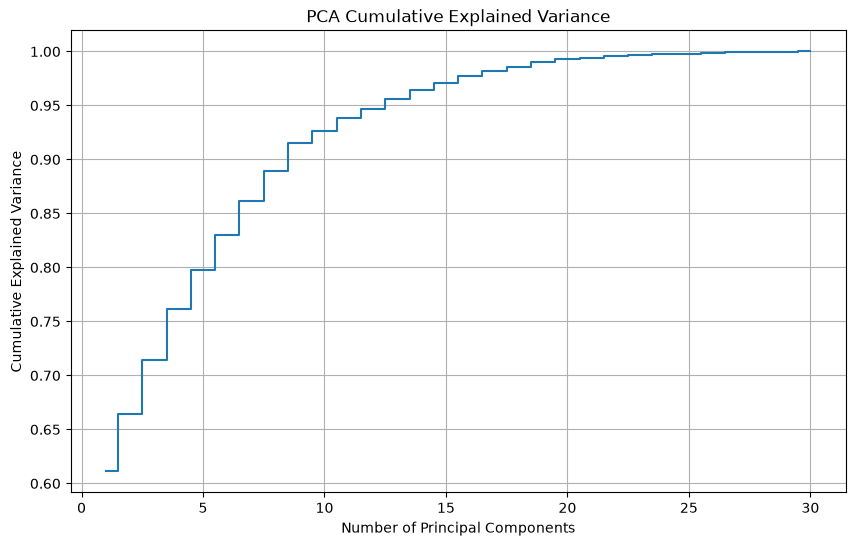

In [139]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 6))

plt.step(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    where='mid'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.grid()
plt.show()

In [140]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Components needed:", n_components)
print("Variance retained:", cumulative_variance[n_components - 1])

Components needed: 13
Variance retained: 0.9559230223044047


In [141]:
pca_df2 = pca_df2.drop(columns=list(range(13, 30)))


In [142]:
pca_df2.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,-0.55,0.01,-0.03,-0.09,0.08,0.03,0.06,-0.03,0.03,0.01,-0.01,0.03,-0.01
1,-0.55,-0.05,0.01,0.02,0.01,-0.01,-0.01,0.06,-0.04,-0.01,0.05,-0.03,0.02
2,-0.56,-0.10,-0.04,0.04,0.14,-0.17,0.02,0.03,-0.02,-0.05,0.01,0.04,-0.00
3,-0.54,-0.16,-0.04,0.03,-0.06,-0.10,-0.04,0.02,0.16,-0.05,0.02,0.02,0.00
4,-0.55,0.02,0.07,0.10,0.01,0.06,0.02,-0.06,0.04,0.03,0.02,0.04,-0.00


In [143]:
import tensorflow as tf
import numpy as np

tf.keras.utils.set_random_seed(42)

In [144]:
from sklearn.ensemble import IsolationForest

# Initialize model
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

# Train and predict anomalies
predictions = iso_forest.fit_predict(X_scaled)

# Check predictions
print(pd.Series(predictions).value_counts())

 1    281958
-1      2849
Name: count, dtype: int64


In [145]:
from sklearn.ensemble import IsolationForest

# Initialize model
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

# Train and predict anomalies
predictions_pca = iso_forest.fit_predict(pca_df2)

# Check predictions
print(pd.Series(predictions_pca).value_counts())

 1    281958
-1      2849
Name: count, dtype: int64


In [146]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

autoencoder = Sequential([
    Input(shape=(X_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(16, activation='relu'),
    Dense(X_scaled.shape[1], activation='linear')
])

autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

history = autoencoder.fit(
    X_scaled,
    X_scaled,
    epochs=20,
    batch_size=256,
    validation_split=0.2,
    shuffle=True
)

Epoch 1/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0279 - val_loss: 0.0017
Epoch 2/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 949us/step - loss: 0.0016 - val_loss: 0.0016
Epoch 3/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0016 - val_loss: 0.0015
Epoch 4/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 929us/step - loss: 0.0016 - val_loss: 0.0015
Epoch 5/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 912us/step - loss: 0.0016 - val_loss: 0.0015
Epoch 6/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 927us/step - loss: 0.0015 - val_loss: 0.0013
Epoch 7/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 907us/step - loss: 0.0014 - val_loss: 0.0012
Epoch 8/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 914us/step - loss: 0.0012 - val_loss: 0.0011
Epoch 9/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 906us/step - loss: 0.0012 - val_loss: 0.0011
Epoch 10/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 975us/step - loss: 0.0011 - val_loss: 0.0010
Epoch 11/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 949us/step - loss: 0.0011 - val_loss: 9.9624e-04
Epoch 12/20
891/891 ━━━━━━━━━━

In [147]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

autoencoder_pca = Sequential([
    Input(shape=(pca_df2.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(16, activation='relu'),
    Dense(pca_df2.shape[1], activation='linear')
])

autoencoder_pca.compile(
    optimizer='adam',
    loss='mse'
)

history = autoencoder_pca.fit(
    pca_df2,
    pca_df2,
    epochs=20,
    batch_size=256,
    validation_split=0.2,
    shuffle=True
)

Epoch 1/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 992us/step - loss: 0.0022 - val_loss: 9.3005e-04
Epoch 2/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 898us/step - loss: 7.1942e-04 - val_loss: 6.4810e-04
Epoch 3/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 956us/step - loss: 6.8555e-04 - val_loss: 5.9390e-04
Epoch 4/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 918us/step - loss: 6.7575e-04 - val_loss: 5.8049e-04
Epoch 5/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 912us/step - loss: 6.7154e-04 - val_loss: 5.8030e-04
Epoch 6/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 6.6216e-04 - val_loss: 5.7604e-04
Epoch 7/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 6.5526e-04 - val_loss: 5.7574e-04
Epoch 8/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 6.5292e-04 - val_loss: 5.7608e-04
Epoch 9/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 6.5155e-04 - val_loss: 5.7655e-04
Epoch 10/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 6.5048e-04 - val_loss: 5.7754e-04
Epoch 11/20
891/891 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step 

In [148]:
reconstructed_pca = autoencoder_pca.predict(pca_df2)

reconstruction_error_pca = np.mean(
    np.square(pca_df2.to_numpy() - reconstructed_pca),
    axis=1
)

8901/8901 ━━━━━━━━━━━━━━━━━━━━ 5s 528us/step


In [149]:
reconstructed = autoencoder.predict(X_scaled)

reconstruction_error = np.mean(
    np.square(X_scaled.to_numpy() - reconstructed),
    axis=1
)

8901/8901 ━━━━━━━━━━━━━━━━━━━━ 5s 583us/step


In [150]:
threshold = np.percentile(reconstruction_error, 99)

autoencoder_predictions = (
    reconstruction_error >= threshold
).astype(int)

isolation_predictions = (predictions == -1).astype(int)

In [151]:
threshold_pca = np.percentile(reconstruction_error_pca, 99)

autoencoder_predictions_pca = (
    reconstruction_error_pca >= threshold_pca
).astype(int)

isolation_predictions_pca = (predictions_pca == -1).astype(int)

In [152]:
y_true = data['Class']

In [153]:
from sklearn.metrics import precision_score, recall_score, f1_score

for name, pred in [
    ('Isolation Forest', isolation_predictions),
    ('Autoencoder', autoencoder_predictions)
]:
    print(name)
    print('Precision:', precision_score(y_true, pred, zero_division=0))
    print('Recall:', recall_score(y_true, pred, zero_division=0))
    print('F1:', f1_score(y_true, pred, zero_division=0))
    print()

Isolation Forest
Precision: 0.10143910143910144
Recall: 0.5873983739837398
F1: 0.1730020951810835

Autoencoder
Precision: 0.13724113724113723
Recall: 0.7947154471544715
F1: 0.2340616581861718



In [154]:
from sklearn.metrics import precision_score, recall_score, f1_score

for name, pred in [
    ('Isolation Forest with PCA', isolation_predictions_pca),
    ('Autoencoder with PCA', autoencoder_predictions_pca)
]:
    print(name)
    print('Precision:', precision_score(y_true, pred, zero_division=0))
    print('Recall:', recall_score(y_true, pred, zero_division=0))
    print('F1:', f1_score(y_true, pred, zero_division=0))
    print()

Isolation Forest with PCA
Precision: 0.12425412425412426
Recall: 0.7195121951219512
F1: 0.21191260101765938

Autoencoder with PCA
Precision: 0.11969111969111969
Recall: 0.693089430894309
F1: 0.2041304998503442



### Evaluation and Fraud Detection Performance

The Credit Card Fraud Detection dataset is highly imbalanced, containing **284,807 transactions, of which only 492 (0.173%) are fraudulent**. Therefore, precision, recall, and F1-score were prioritized over accuracy.

Two anomaly detection models, **Isolation Forest and Autoencoder**, were evaluated both with and without Principal Component Analysis (PCA). The models were trained and evaluated on the full dataset, so the reported results represent in-sample performance rather than independent test performance.

| Model | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Isolation Forest | 10.14% | 58.74% | 17.30% |
| **Autoencoder** | **13.72%** | **79.47%** | **23.41%** |
| Isolation Forest + PCA | 12.43% | 71.95% | 21.19% |
| Autoencoder + PCA | 11.97% | 69.31% | 20.41% |

**Key Findings:**

- **Autoencoder without PCA achieved the highest overall performance**, with 13.72% precision, 79.47% recall, and 23.41% F1-score.
- The Autoencoder successfully detected **391 out of 492 fraudulent transactions**, missing 101 fraudulent cases.
- PCA improved Isolation Forest's performance, increasing recall from 58.74% to 71.95% and F1-score from 17.30% to 21.19%.
- Applying PCA to the Autoencoder reduced its performance, suggesting that some information useful for detecting anomalies may have been lost during dimensionality reduction.
- All four models exhibited relatively low precision, indicating a substantial number of false positives.

**Overall Conclusion:**

The Autoencoder without PCA demonstrated the strongest anomaly detection performance in this experiment, achieving the highest precision, recall, and F1-score among the four evaluated configurations.

The results demonstrate that PCA can improve Isolation Forest's performance, but it does not necessarily benefit reconstruction-based models such as Autoencoders.

Although the Autoencoder detected approximately 79% of fraudulent transactions, its low precision indicates that many legitimate transactions were incorrectly flagged as suspicious.

These findings highlight the potential of anomaly detection for identifying unusual financial transactions, while emphasizing the importance of reducing false positives.

**Limitation:** Because the models were trained and evaluated on the same dataset, these results do not establish performance on unseen transactions. Future work should include independent test-set evaluation, threshold optimization, and feature engineering to assess generalization and improve detection reliability.

In [155]:

from sklearn.metrics import classification_report, confusion_matrix

models = {
    "Isolation Forest": isolation_predictions,
    "Autoencoder": autoencoder_predictions,
    "Isolation Forest + PCA": isolation_predictions_pca,
    "Autoencoder + PCA": autoencoder_predictions_pca
}

for name, predictions in models.items():
    print(f"\n{'=' * 45}")
    print(name)
    print('=' * 45)

    print(classification_report(
        y_true,
        predictions,
        labels=[0, 1],
        target_names=["Normal", "Fraud"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ))



Isolation Forest
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00    284315
       Fraud       0.10      0.59      0.17       492

    accuracy                           0.99    284807
   macro avg       0.55      0.79      0.58    284807
weighted avg       1.00      0.99      0.99    284807

Confusion Matrix:
[[281755   2560]
 [   203    289]]

Autoencoder
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00    284315
       Fraud       0.14      0.79      0.23       492

    accuracy                           0.99    284807
   macro avg       0.57      0.89      0.61    284807
weighted avg       1.00      0.99      0.99    284807

Confusion Matrix:
[[281857   2458]
 [   101    391]]

Isolation Forest + PCA
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00    284315
       Fraud       0.12      0.72      0.21       492

    accuracy         

In [156]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1-score": f1_score(y_true, predictions)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Model,Precision,Recall,F1-score
0,Isolation Forest,0.10,0.59,0.17
1,Autoencoder,0.14,0.79,0.23
2,Isolation Forest + PCA,0.12,0.72,0.21
3,Autoencoder + PCA,0.12,0.69,0.20


In [163]:
df_insights = data.copy()

df_insights['Predicted'] = autoencoder_predictions

anomalies = df_insights[df_insights['Predicted'] == 1]
normal = df_insights[df_insights['Predicted'] == 0]

print("Flagged transactions:", len(anomalies))
print("Normal transactions:", len(normal))

Flagged transactions: 2849
Normal transactions: 281958


In [164]:
print("Flagged transactions:")
print(anomalies['Amount'].describe())

print("\nNormal transactions:")
print(normal['Amount'].describe())

Flagged transactions:
count    2849.00
mean      529.85
std      1468.69
min         0.00
25%         2.23
50%        34.27
75%       212.53
max     25691.16
Name: Amount, dtype: float64

Normal transactions:
count   281958.00
mean        83.89
std        198.53
min          0.00
25%          5.67
50%         22.00
75%         76.36
max       4229.51
Name: Amount, dtype: float64


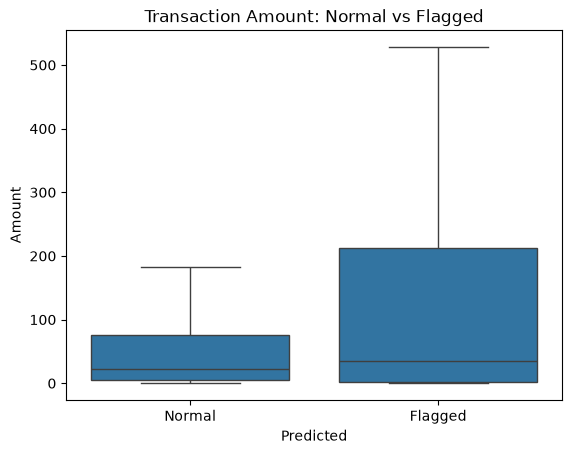

In [165]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.boxplot(
    data=df_insights,
    x='Predicted',
    y='Amount',
    showfliers=False
)

plt.xticks([0, 1], ['Normal', 'Flagged'])
plt.title('Transaction Amount: Normal vs Flagged')
plt.show()

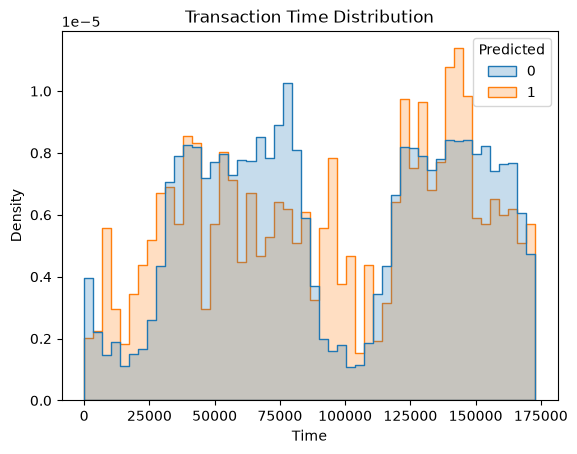

In [166]:
sns.histplot(
    data=df_insights,
    x='Time',
    hue='Predicted',
    bins=50,
    stat='density',
    common_norm=False,
    element='step'
)

plt.title('Transaction Time Distribution')
plt.show()

In [167]:
print(pd.crosstab(
    df_insights['Predicted'],
    df_insights['Class'],
    rownames=['Prediction'],
    colnames=['Actual Class']
))

Actual Class       0    1
Prediction               
0             281857  101
1               2458  391


In [168]:
features = [f'V{i}' for i in range(1, 29)]

comparison = pd.DataFrame({
    'Normal': normal[features].mean(),
    'Flagged': anomalies[features].mean()
})

comparison['Difference'] = abs(
    comparison['Flagged'] - comparison['Normal']
)

comparison.sort_values(
    'Difference',
    ascending=False
).head(10)

,Normal,Flagged,Difference
V1,0.08,-8.16,8.24
V3,0.04,-4.17,4.21
V4,-0.02,1.86,1.88
V7,0.02,-1.60,1.62
V8,0.02,-1.59,1.60
V14,0.02,-1.55,1.56
V5,0.01,-1.35,1.37
V9,-0.01,1.07,1.08
V10,-0.01,1.01,1.02
V2,0.01,-1.01,1.02


### Insights: Detected Anomalies

**Which types of transactions were flagged?**

The Autoencoder without PCA flagged **2,849 transactions (approximately 1% of the dataset)**.

Flagged transactions had a significantly higher average transaction amount of **$529.85**, compared with **$83.89** for non-flagged transactions.

However, not all flagged transactions involved large amounts. Approximately 25% had transaction amounts of **$2.23 or less**, indicating that anomalies were not limited to high-value transactions.

**What patterns exist in detected anomalies?**

- **Higher transaction amounts:** Flagged transactions had an average amount approximately 6.3 times higher than non-flagged transactions.
- **Greater variability:** Flagged amounts showed substantially greater variability, with a standard deviation of $1,468.69 compared with $198.53 for normal predictions.
- **Low-value anomalies:** The model also flagged low-value transactions, suggesting that unusual patterns may exist across different transaction amounts.
- **Fraud detection:** Of the 2,849 flagged transactions, **391 were actual fraud cases**, while 2,458 were legitimate transactions incorrectly flagged.
- **Feature differences:** V1, V3, and V4 showed the largest absolute differences in mean values between flagged and non-flagged transactions, suggesting that these features may help distinguish anomalous transaction patterns.

**Overall Conclusion:**

The Autoencoder without PCA identified transactions exhibiting unusual characteristics, including higher transaction amounts, greater variability, and differences in PCA-derived transaction features.

The model detected **79.47% of fraudulent transactions**, achieving **13.72% precision**. However, the relatively low precision indicates that many legitimate transactions were incorrectly classified as suspicious.

These findings demonstrate the potential of Autoencoder-based anomaly detection for identifying unusual financial transactions while highlighting the need to reduce false positives and improve detection reliability.

*Note: These insights are based on in-sample predictions because the model was trained and evaluated on the same dataset.*